# Implementacion Algoritmo - Backtracking

In [4]:
import time
from itertools import product, permutations

In [5]:
class Tarea:
    def __init__(self, id: str, tiempo: int, prioridad: int, dependencias: list[str]):
        self.id = id
        self.tiempo = tiempo
        self.prioridad = prioridad
        self.dependencias = dependencias

    def __repr__(self):
        return str(self.id)

### Complejidades

- #### Metodo __init__
    - complejidad temporal: O(1)
    - complejidad espacial: O(1)
- #### Metodo __repr__
    - complejidad temporal: O(1)
    - complejidad espacial: O(1)

In [6]:
def backtracking_servidores(tareas: list[Tarea], num_servidores: int):
    mapa_tareas = {t.id: t for t in tareas}
    total_tareas = len(tareas)

    mejor_tiempo = float("inf")
    mejor_costo = float("inf")
    mejor_orden = None
    mejor_asignacion = None

    def resolver(completadas: set, fin_tarea: dict, fin_servidor: list, orden_actual: list, asignacion_actual: list):
        nonlocal mejor_tiempo, mejor_costo, mejor_orden, mejor_asignacion

        tiempo_actual = max(fin_servidor, default=0)
        if tiempo_actual > mejor_tiempo:
            return

        if len(completadas) == total_tareas:
            costo_prioridad = sum(t.prioridad * fin_tarea[t.id] for t in tareas)

            if tiempo_actual < mejor_tiempo or (tiempo_actual == mejor_tiempo and costo_prioridad < mejor_costo):
                mejor_tiempo = tiempo_actual
                mejor_costo = costo_prioridad
                mejor_orden = list(orden_actual)
                mejor_asignacion = tuple(asignacion_actual)
            return

        disponibles = [
            t for t in tareas 
            if t.id not in completadas and all(dep in completadas for dep in t.dependencias)
        ]

        for tarea in disponibles:
            fin_deps = max((fin_tarea[dep] for dep in tarea.dependencias), default=0)

            for s in range(num_servidores):
                inicio = max(fin_servidor[s], fin_deps)
                fin = inicio + tarea.tiempo

                if fin > mejor_tiempo:
                    continue

                t_libre_previo = fin_servidor[s]
                fin_servidor[s] = fin
                fin_tarea[tarea.id] = fin
                completadas.add(tarea.id)
                orden_actual.append(tarea)
                asignacion_actual.append(s)

                resolver(completadas, fin_tarea, fin_servidor, orden_actual, asignacion_actual)

                fin_servidor[s] = t_libre_previo
                del fin_tarea[tarea.id]
                completadas.remove(tarea.id)
                orden_actual.pop()
                asignacion_actual.pop()

    resolver(
        completadas=set(),
        fin_tarea={},
        fin_servidor=[0] * num_servidores,
        orden_actual=[],
        asignacion_actual=[]
    )

    return (mejor_tiempo, mejor_orden, mejor_asignacion)

### Complejidades

- #### Método "backtracking_servidores"
    - complejidad temporal: O(n! · mⁿ · n²)
    - complejidad espacial: O(n² + m)

- #### Método "resolver"
    - complejidad temporal: O(n! · mⁿ · n²)
    - complejidad espacial: O(n² + m)

# Pruebas

In [7]:
servidores_pequeño = 2
tareas_pequeño = [
    Tarea("A", 5, 2, []),
    Tarea("B", 3, 1, ["A"]),
    Tarea("C", 4, 3, ["A"]),
    Tarea("D", 2, 1, ["B", "C"]),
]

In [8]:
servidores_mediano = 3
tareas_mediano = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
]

In [9]:
servidores_grande = 3
tareas_grande = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
]

In [10]:
casos = [
    ("Pequeño", tareas_pequeño, servidores_pequeño),
    ("Mediano", tareas_mediano, servidores_mediano),
    ("Grande", tareas_grande, servidores_grande),
]

for nombre, tareas, servidores in casos:
    inicio = time.perf_counter()
    resultado = backtracking_servidores(tareas, servidores)
    fin = time.perf_counter()
    print(f"{nombre} (Backtracking): {resultado}")
    print(f"Tiempo: {fin - inicio:.6f} segundos\n")

Pequeño (Backtracking): (11, [A, B, C, D], (0, 0, 1, 0))
Tiempo: 0.000096 segundos

Mediano (Backtracking): (32, [B, A, C, D, E, F, G, H, I], (0, 1, 1, 2, 0, 1, 0, 1, 0))
Tiempo: 0.775075 segundos

Grande (Backtracking): (32, [B, A, C, D, E, F, G, H, I, J], (0, 1, 1, 2, 0, 1, 0, 1, 0, 2))
Tiempo: 6.760474 segundos



# Grafica

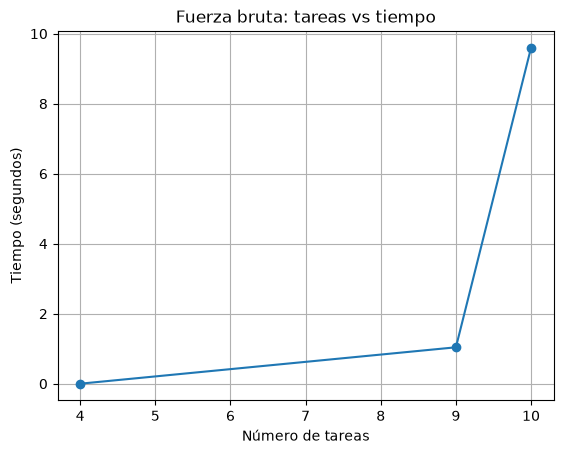

In [12]:
import matplotlib.pyplot as plt

tareas = [4, 9, 10]
tiempos = [0.000370, 1.040323, 9.599288]

plt.plot(tareas, tiempos, marker="o")
plt.xlabel("Número de tareas")
plt.ylabel("Tiempo (segundos)")
plt.title("Fuerza bruta: tareas vs tiempo")
plt.grid(True)
plt.savefig("Backtracking_tiempos.png", dpi=150)
plt.show()